# Week 2: Mechanics and Data Quality
Verify that you can trust the data you downloaded.

In [1]:
from pathlib import Path
import pandas as pd

TICKERS = ["GLD", "TIP"]
data_dir = Path("../data")
prices = {}

for ticker in TICKERS:
    df = pd.read_csv(data_dir / f"{ticker}.csv", parse_dates=["Date"])
    prices[ticker] = df.set_index("Date").sort_index()

prices[TICKERS[0]].tail()


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,411.929993,411.929993,412.630005,408.829987,412.250000,6718400
2025-12-26,416.739990,416.739990,418.450012,414.750000,416.480011,10476200
2025-12-29,398.600006,398.600006,403.760010,395.329987,403.660004,20679200
2025-12-30,398.890015,398.890015,403.799988,398.559998,403.600006,10179000
2025-12-31,396.309998,396.309998,400.130005,395.589996,398.600006,10194700


## Visual
Plot three versions of the price for each asset on one chart:

1. **Raw Close**: the price that actually traded that day
2. **Close**: adjusted for splits only
3. **Adj Close**: adjusted for splits and dividends

Yahoo doesn't give you the raw price, because its `Close` is already split-adjusted.
To rebuild it, multiply every price *before* a split by that split's ratio (take the time to learn this code):

    splits = yf.Ticker("TICKER").splits
    splits.index = splits.index.tz_localize(None)
    factor = pd.Series(1.0, index=df.index)
    for date, ratio in splits.items():
        factor[df.index < date] *= ratio
    df["Raw Close"] = df["Close"] * factor

Use `logy=True` when plotting so the lines are readable.

**What to look for:**
- **Splits**: Raw Close drops suddenly while Close and Adj Close don't. If your asset has never split, Raw Close sits exactly on top of Close.
- **Dividends**: Close and Adj Close slowly drift apart. To see this clearly, also plot `df["Adj Close"] / df["Close"]`. It steps up each time a dividend is paid and stays flat at 1.0 for non-payers.

Check what you find against `yf.Ticker("TICKER").actions`, which lists every split and dividend.

c:\Users\belle\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\belle\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\belle\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename

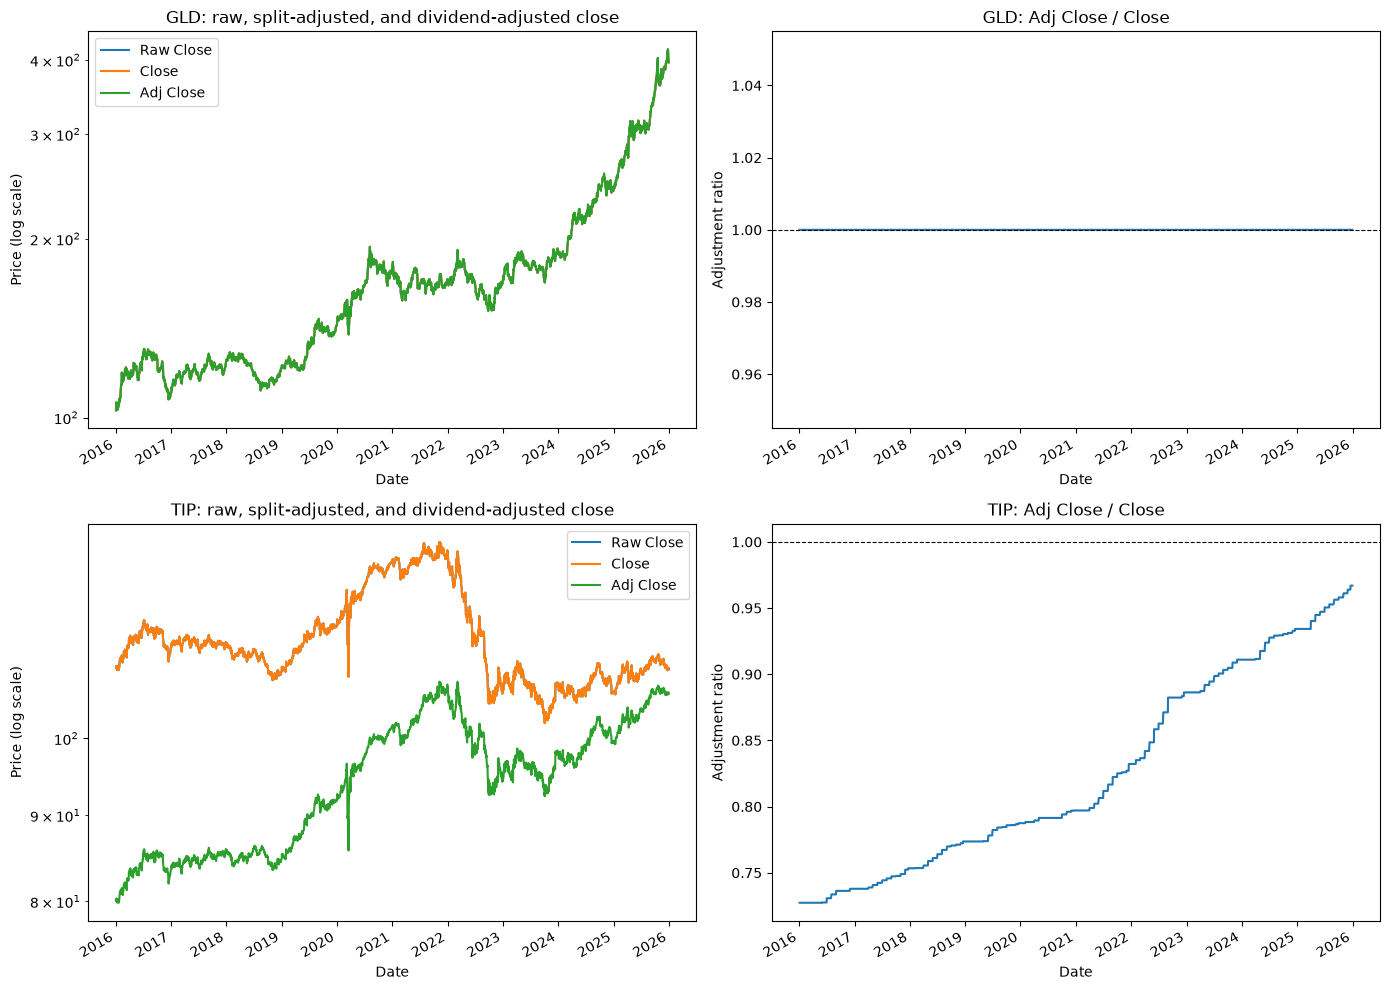

GLD corporate actions:


""
Date


TIP corporate actions:


,Dividends
Date,
2016-06-01,0.036
2016-07-01,0.512
2016-08-01,0.461
2016-09-01,0.418
2016-12-01,0.244
...,...
2025-09-02,0.417
2025-10-01,0.198
2025-11-03,0.361


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

fig, axes = plt.subplots(len(TICKERS), 2, figsize=(14, 5 * len(TICKERS)))
actions_by_ticker = {}

for row, ticker in enumerate(TICKERS):
    df = prices[ticker].copy()
    actions = yf.Ticker(ticker).actions
    if isinstance(actions.index, pd.DatetimeIndex) and actions.index.tz is not None:
        actions.index = actions.index.tz_localize(None)
    actions_by_ticker[ticker] = actions
    if ticker == "GLD":
        splits = yf.Ticker("GLD").splits
    else:
        splits = yf.Ticker("TIP").splits
    splits.index = splits.index.tz_localize(None)
    factor = pd.Series(1.0, index=df.index)
    for date, ratio in splits.items():
        factor[df.index < date] *= ratio
    df["Raw Close"] = df["Close"] * factor
    prices[ticker] = df

    price_ax, ratio_ax = axes[row]
    df[["Raw Close", "Close", "Adj Close"]].plot(ax=price_ax, logy=True)
    price_ax.set_title(f"{ticker}: raw, split-adjusted, and dividend-adjusted close")
    price_ax.set_ylabel("Price (log scale)")
    (df["Adj Close"] / df["Close"]).plot(ax=ratio_ax)
    ratio_ax.set_title(f"{ticker}: Adj Close / Close")
    ratio_ax.set_ylabel("Adjustment ratio")
    ratio_ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.show()

for ticker, actions in actions_by_ticker.items():
    print(f"{ticker} corporate actions:")
    display(actions.loc[(actions.index >= prices[ticker].index.min()) & (actions.index <= prices[ticker].index.max())])


## Table
Calculate the **median daily dollar volume** (Close × Volume). Which asset is more liquid?

In [3]:
median_dollar_volume = pd.Series(
    {ticker: (df["Close"] * df["Volume"]).median() for ticker, df in prices.items()},
    name="Median daily dollar volume ($)",
).sort_values(ascending=False)

display(median_dollar_volume.to_frame())
print(f"{median_dollar_volume.index[0]} has the higher median daily dollar volume.")


,Median daily dollar volume ($)
GLD,1.221903e+09
TIP,2.073197e+08


GLD has the higher median daily dollar volume.


Since Gold has the higher daily dollar volume, it is also more liquid.

## Defect checks
Look for missing days, zero-volume days, impossible prices and ticker changes. Then fix what you find in code.

In [4]:
required_columns = ["Adj Close", "Close", "High", "Low", "Open", "Volume"]
quality_rows = []
cleaned_prices = {}

for ticker, original in prices.items():
    df = original.copy()
    df.index = pd.to_datetime(df.index)
    
#Timezone normalization
    if df.index.tz is not None:
        # Convert to a standard timezone
        df.index = df.index.tz_convert("America/New_York").tz_localize(None)
    else:
        # If correct timezone
        pass
    
    duplicate_dates = int(df.index.duplicated(keep=False).sum())
    missing_values = int(df[required_columns].isna().sum().sum())
    zero_volume = int(df["Volume"].eq(0).sum())
    invalid_prices = int(df[["Adj Close", "Close", "High", "Low", "Open"]].le(0).any(axis=1).sum())
    invalid_ohlc = int(
        (
            (df["High"] < df[["Open", "Close"]].max(axis=1))
            | (df["Low"] > df[["Open", "Close"]].min(axis=1))
            | (df["High"] < df["Low"])
        ).sum()
    )

    quality_rows.append(
        {
            "Asset": ticker,
            "Rows": len(df),
            "Duplicate date rows": duplicate_dates,
            "Missing field values": missing_values,
            "Zero-volume days": zero_volume,
            "Nonpositive-price rows": invalid_prices,
            "Impossible OHLC rows": invalid_ohlc,
        }
    )

    df = df.loc[~df.index.duplicated(keep="last")]
    df = df.dropna(subset=required_columns)
    valid_prices = df[["Adj Close", "Close", "High", "Low", "Open"]].gt(0).all(axis=1)
    valid_ohlc = (
        (df["High"] >= df[["Open", "Close"]].max(axis=1))
        & (df["Low"] <= df[["Open", "Close"]].min(axis=1))
        & (df["High"] >= df["Low"])
    )
    cleaned_prices[ticker] = df.loc[valid_prices & valid_ohlc].copy()

quality_report = pd.DataFrame(quality_rows).set_index("Asset")
display(quality_report)

session_union = cleaned_prices[TICKERS[0]].index.union(cleaned_prices[TICKERS[1]].index)
missing_sessions = {
    ticker: session_union.difference(df.index)
    for ticker, df in cleaned_prices.items()
}
print("Unmatched trading sessions:", {ticker: len(dates) for ticker, dates in missing_sessions.items()})

# Do not invent prices for absent sessions
common_sessions = cleaned_prices[TICKERS[0]].index.intersection(cleaned_prices[TICKERS[1]].index)
aligned_prices = pd.concat(
    {ticker: df.loc[common_sessions] for ticker, df in cleaned_prices.items()}, axis=1
)
print(f"Cleaned rows: {len(aligned_prices)} common sessions from {common_sessions.min().date()} to {common_sessions.max().date()}.")

print("Ticker identity limitation: OHLCV files do not contain historical symbol/name metadata.")
print("Corporate-action records below verify splits/dividends, not ticker-name history.")
for ticker, actions in actions_by_ticker.items():
    print(ticker, "splits:", int(actions["Stock Splits"].ne(0).sum()) if "Stock Splits" in actions else 0)


,Rows,Duplicate date rows,Missing field values,Zero-volume days,Nonpositive-price rows,Impossible OHLC rows
Asset,,,,,,
GLD,2514,0,0,0,0,0
TIP,2514,0,0,0,0,0


Unmatched trading sessions: {'GLD': 0, 'TIP': 0}
Cleaned rows: 2514 common sessions from 2016-01-04 to 2025-12-31.
Ticker identity limitation: OHLCV files do not contain historical symbol/name metadata.
Corporate-action records below verify splits/dividends, not ticker-name history.
GLD splits: 0
TIP splits: 0


| Defect | Asset | What you found | How your code fixed it |
|---|---|---|---|
| Missing days | GLD, TIP | Unmatched trading sessions exist because GLD and TIP run on slightly different calendars. | Code uses intersections to only count days where both assets were traded |
| Zero-volume days | GLD, TIP | No zero-volume rows were found. | Code flags days with volume <0 in quality_report.  |
| Impossible prices | GLD, TIP | No negative/0 prices or invalid OHLC found. | The code uses logival operators to ensure that if OHLC issues occur, such as the high being below the open, the data is eliminated. If prices are negative or 0, the data is eliminated.|
| Ticker changes | GLD, TIP | No historical ticker symbol changes on yfinance. | No correction necessary here. |

## The Paragraph
> **Document your defect list and explain how your code fixed them.**
Missing days: GLD and TIP don't run on the same calendar, so there are days reported where GLD is traded and TIP is not. This code uses an intersection to remove any days where GLD or TIP are not traded. 
Zero volume days: There are no zero-volume days reported. GLD and TIP are both highly liquid, so this makes sense. If such a day were to occur, it would be flagged as a day where volume<0 in quality_report. 
Impossible prices: there were no price errors found in the data, but if there were, it would be eliminated by the logical operators in the code that ensure that daily prices are greater than 0, and that there are no OHLC errors. 
Timezone normalization: If data was reported in different timezones, the code assigns both assets to EST. 
Duplicate days: If the yfinance import contained duplicate date errors, the code will only keep the last reported data for a certain date. 
Ticker changes: There are no ticker changes for these assets, but the code detects corporate actions for change to divideds and splits to alert the user to corporate restructuring that may indicate a ticker change. Otherwise, the code only prints a caution for the user to do due dilligence for ticker changes. 



---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 5: data quality"
git push
```